$Step-1$: **Load the data**

In [1]:
import pandas as pd
df = pd.read_csv("telecom_customer_churn.csv")
print(df.shape)
print(df.columns)
df

(7043, 38)
Index(['Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents',
       'City', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Customer Status', 'Churn Category', 'Churn Reason'],
      dtype='object')


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.60,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,9987-LUTYD,Female,20,No,0,La Mesa,91941,32.759327,-116.997260,0,...,Credit Card,55.15,742.90,0.00,0,606.84,1349.74,Stayed,NaN,NaN
7039,9992-RRAMN,Male,40,Yes,0,Riverbank,95367,37.734971,-120.954271,1,...,Bank Withdrawal,85.10,1873.70,0.00,0,356.40,2230.10,Churned,Dissatisfaction,Product dissatisfaction
7040,9992-UJOEL,Male,22,No,0,Elk,95432,39.108252,-123.645121,0,...,Credit Card,50.30,92.75,0.00,0,37.24,129.99,Joined,NaN,NaN
7041,9993-LHIEB,Male,21,Yes,0,Solana Beach,92075,33.001813,-117.263628,5,...,Credit Card,67.85,4627.65,0.00,0,142.04,4769.69,Stayed,NaN,NaN


In [54]:
# this shows how many customers stayed, churned, or joined.

print(df['Customer Status'].value_counts())

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


$Step-2$: **Clean the target and check for missing values**

In [55]:
df = df[df['Customer Status'] != 'Joined'].copy()        # this line "not= Joined" means copy "stayed & churned". then stored in dataset
df['Churn'] = (df['Customer Status'] == 'Churned').astype(int)  
# gives True for churned customers and False for the rest.astype(int) turns True into 1 and False into 0.

print(df.shape)
print(df['Churn'].value_counts())      # counts how many 0s and 1s there are

missing = df.isnull().sum()
print(missing[missing > 0])     # this will print columns which columns contains blank

(6589, 39)
Churn
0    4720
1    1869
Name: count, dtype: int64
Offer                                3598
Avg Monthly Long Distance Charges     644
Multiple Lines                        644
Internet Type                        1344
Avg Monthly GB Download              1344
Online Security                      1344
Online Backup                        1344
Device Protection Plan               1344
Premium Tech Support                 1344
Streaming TV                         1344
Streaming Movies                     1344
Streaming Music                      1344
Unlimited Data                       1344
Churn Category                       4720
Churn Reason                         4720
dtype: int64


In [56]:
# for checking and understanding purpose only
print(df['Churn Category'].value_counts())
print("*************************")
print(df['Churn Reason'].value_counts())

Churn Category
Competitor         841
Dissatisfaction    321
Attitude           314
Price              211
Other              182
Name: count, dtype: int64
*************************
Churn Reason
Competitor had better devices                313
Competitor made better offer                 311
Attitude of support person                   220
Don't know                                   130
Competitor offered more data                 117
Competitor offered higher download speeds    100
Attitude of service provider                  94
Price too high                                78
Product dissatisfaction                       77
Network reliability                           72
Long distance charges                         64
Service dissatisfaction                       63
Moved                                         46
Extra data charges                            39
Limited range of services                     37
Poor expertise of online support              31
Lack of affordable do

$Step-3$: **Fill the blanks**

- Since a blank means doesn’t have this service, we fill text columns with the word "None" and numeric columns with 0.

- Models can’t work with blank cells.

In [57]:
# Text columns: blank means the customer doesn't have this service/offer
none_cols = ['Offer', 'Multiple Lines', 'Internet Type', 'Online Security',
             'Online Backup', 'Device Protection Plan', 'Premium Tech Support',
             'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data']        # list of the text columns
df[none_cols] = df[none_cols].fillna('None')     # replaces every blank in those columns with the text “None”.


# Numeric columns: no service means 0 charges / 0 GB
num_cols = ['Avg Monthly Long Distance Charges', 'Avg Monthly GB Download']
df[num_cols] = df[num_cols].fillna(0)       # same for the two numeric columns, using the number 0.


# Check what is still blank
missing = df.isnull().sum()
print(missing[missing > 0])

Churn Category    4720
Churn Reason      4720
dtype: int64


$Step-4$: **Make a separate dataset for modeling**

In [58]:
# Full copy for EDA (keeps churn reasons)
df_eda = df.copy()                            # saves a full version with all 39 columns

# Modeling copy: drop leakage and useless columns
drop_cols = ['Customer Status', 'Churn Category', 'Churn Reason',           # Customer Status, Churn Category and Churn Reason are data leakage
             'Customer ID','Zip Code', 'Latitude', 'Longitude']   # Customer ID, Zip Code, Latitude and Longitude are don’t describe customer behavior

df_model = df.drop(columns=drop_cols)   # removes those 7 columns and stores the result in df_model.

print(df_model.shape)

(6589, 32)


- now we have two datasets:

    - df_model: the 32 columns the model will learn from (31 features plus the Churn target).

    - df_eda: the full version, which we’ll use for plots.

In [59]:
df_eda.head(10)          # it contain all columns

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason,Churn
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,65.60,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN,0
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,-4.00,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN,0
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices,1
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction,1
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability,1
5,0013-MHZWF,Female,23,No,3,Midpines,95345,37.581496,-119.972762,0,...,69.40,571.45,0.00,0,150.93,722.38,Stayed,NaN,NaN,0
6,0013-SMEOE,Female,67,Yes,0,Lompoc,93437,34.757477,-120.550507,1,...,109.70,7904.25,0.00,0,707.16,8611.41,Stayed,NaN,NaN,0
7,0014-BMAQU,Male,52,Yes,0,Napa,94558,38.489789,-122.270110,8,...,84.65,5377.80,0.00,20,816.48,6214.28,Stayed,NaN,NaN,0
8,0015-UOCOJ,Female,68,No,0,Simi Valley,93063,34.296813,-118.685703,0,...,48.20,340.35,0.00,0,73.71,414.06,Stayed,NaN,NaN,0
9,0016-QLJIS,Female,43,Yes,1,Sheridan,95681,38.984756,-121.345074,3,...,90.45,5957.90,0.00,0,1849.90,7807.80,Stayed,NaN,NaN,0


In [60]:
df_model.head(10)           # it does not contain all columns

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Churn
0,Female,37,Yes,0,Frazier Park,2,9,None,Yes,42.39,...,One Year,Yes,Credit Card,65.60,593.30,0.00,0,381.51,974.81,0
1,Male,46,No,0,Glendale,0,9,None,Yes,10.69,...,Month-to-Month,No,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,0
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,Month-to-Month,Yes,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,1
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,Month-to-Month,Yes,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,1
4,Female,75,Yes,0,Camarillo,3,3,None,Yes,7.38,...,Month-to-Month,Yes,Credit Card,83.90,267.40,0.00,0,22.14,289.54,1
5,Female,23,No,3,Midpines,0,9,Offer E,Yes,16.77,...,Month-to-Month,Yes,Credit Card,69.40,571.45,0.00,0,150.93,722.38,0
6,Female,67,Yes,0,Lompoc,1,71,Offer A,Yes,9.96,...,Two Year,Yes,Bank Withdrawal,109.70,7904.25,0.00,0,707.16,8611.41,0
7,Male,52,Yes,0,Napa,8,63,Offer B,Yes,12.96,...,Two Year,Yes,Credit Card,84.65,5377.80,0.00,20,816.48,6214.28,0
8,Female,68,No,0,Simi Valley,0,7,Offer E,Yes,10.53,...,Two Year,Yes,Bank Withdrawal,48.20,340.35,0.00,0,73.71,414.06,0
9,Female,43,Yes,1,Sheridan,3,65,None,Yes,28.46,...,Two Year,Yes,Credit Card,90.45,5957.90,0.00,0,1849.90,7807.80,0


$Step-5$: **EDA plot 1, churn rate by contract type**

In [61]:
# for understanding how contract is grouping
df_eda['Contract'].value_counts()

Contract
Month-to-Month    3202
Two Year          1861
One Year          1526
Name: count, dtype: int64

In [62]:
# for understanding
print(((df_eda['Contract'] == 'Month-to-Month') & (df_eda['Churn'] == 1)).sum())
print(((df_eda['Contract'] == 'One Year') & (df_eda['Churn'] == 1)).sum())
print(((df_eda['Contract'] == 'Two Year') & (df_eda['Churn'] == 1)).sum())

# mean value
print(1655/3202)
print(166/1526)
print(48/1861)

1655
166
48
0.5168644597126796
0.10878112712975098
0.025792584631918324


Contract
Month-to-Month    51.686446
One Year          10.878113
Two Year           2.579258
Name: Churn, dtype: float64


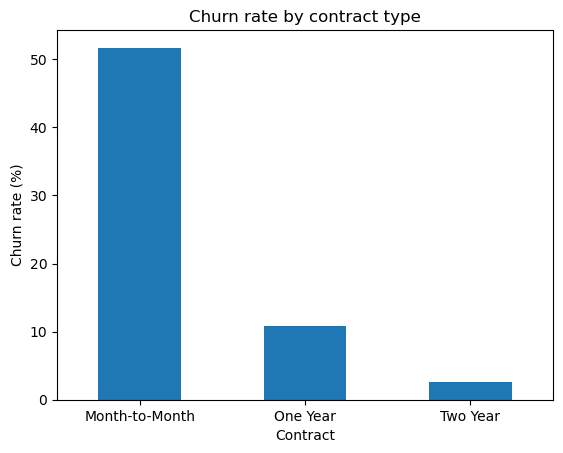

In [63]:


import matplotlib.pyplot as plt

rate = df_eda.groupby('Contract')['Churn'].mean()*100   # It will group contract 3 types and for each type it will calculate mean value
print(rate)

rate.plot(kind='bar')
plt.title('Churn rate by contract type')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)         # below lables Month-to-Month, Onr Year, Two Year
plt.show()

$Step-6$: **EDA plot 2, tenure for churned vs stayed customers**

- Tenure is how many months a customer has been with the company

- A histogram shows this by grouping tenure into bins (for example 0-2 months, 2-4 months)

In [64]:
df_eda['Tenure in Months'].min()       # staring with 1 month

df_eda['Tenure in Months'].max()      # last month 72 

72

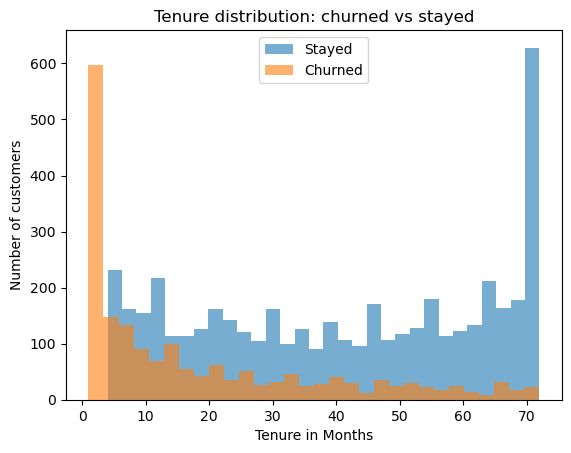

In [65]:
stayed = df_eda[df_eda['Churn'] == 0]['Tenure in Months']
churned = df_eda[df_eda['Churn'] == 1]['Tenure in Months']            

stayed.plot(kind='hist', bins=30, alpha=0.6, label='Stayed')
churned.plot(kind='hist',bins=30, alpha=0.6, label='Churned')

plt.title("Tenure distribution: churned vs stayed")
plt.ylabel("Number of customers")
plt.xlabel("Tenure in Months")
plt.legend()
plt.show()

- Churn is concentrated in the first few months: 

- nearly 600 customers churned(left the service) within roughly 2-3 months, and churn drops steadily as tenure grows. 
    
- Customers who stay past the first year are much less likely to leave, 
    and the largest group of stayers has been with the company for around 70+ months.

$Step-7$: **EDA plot 3, monthly charge for churned vs stayed**

- Now we check whether customers who pay more are more likely to leave.

In [66]:
df_eda['Monthly Charge'].min()    

df_eda['Monthly Charge'].max()

118.75

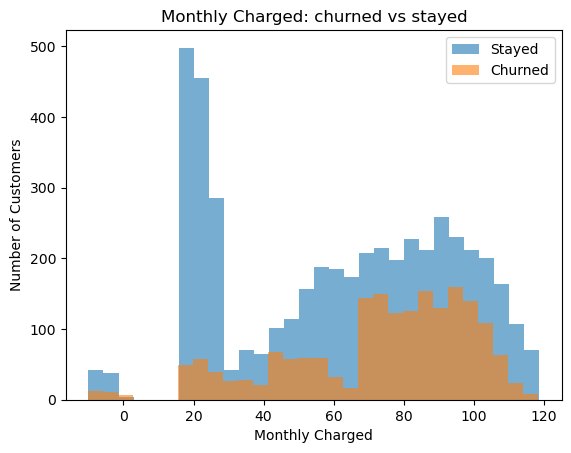

In [67]:
stayed = df_eda[df_eda['Churn'] == 0]['Monthly Charge']
churned = df_eda[df_eda['Churn'] == 1]['Monthly Charge']

stayed.plot(kind='hist', bins=30, alpha=0.6, label='Stayed')
churned.plot(kind='hist', bins=30, alpha=0.6, label='Churned')

plt.title("Monthly Charged: churned vs stayed")
plt.ylabel("Number of Customers")
plt.xlabel("Monthly Charged")
plt.legend()
plt.show()

- From the graph we can say around 500 stayed peoples paying $ 20, around 250 to 260 peoples paying $ 80 to $ 100, around 50 peoples paying $ 115

- When we come to Churned: around 50 poples paying $ 10 to $ 70, around 100 to 130 peoples paying $ 70 to $ 105, around 50 peoples paying around $ 105 rupees

$Step-7b$: **Check it with numbers**

In [68]:
df_eda['Churn'].value_counts()

Churn
0    4720
1    1869
Name: count, dtype: int64

In [69]:
print(df_eda.groupby('Churn')['Monthly Charge'].mean())
print(df_eda['Monthly Charge'].describe())

Churn
0    61.737415
1    73.347592
Name: Monthly Charge, dtype: float64
count    6589.000000
mean       65.030695
std        31.100727
min       -10.000000
25%        35.800000
50%        71.050000
75%        90.400000
max       118.750000
Name: Monthly Charge, dtype: float64


- What your output means

    - The average monthly charge of the 4720 stayed customers is 61.74.
    - The average monthly charge of the 1869 churned customers is 73.35.
    - The difference is 73.35 - 61.74 = 11.61, so churned customers pay about 11.6 more per month on average.

$Step-8$: **EDA plot 4, churn rate by internet type**

- now check which kind of internet service has the most churn

In [70]:
df_eda['Internet Type'].value_counts()        # 4 group will form when we use groupby

Internet Type
Fiber Optic    2934
DSL            1537
None           1344
Cable           774
Name: count, dtype: int64

Internet Type
Cable          27.519380
DSL            19.973975
Fiber Optic    42.126789
None            8.407738
Name: Churn, dtype: float64


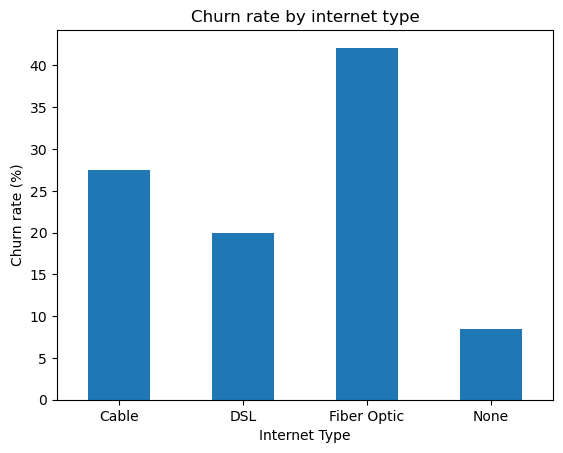

In [73]:
rate = df_eda.groupby('Internet Type')['Churn'].mean()*100
print(rate)

rate.plot(kind='bar')
plt.title("Churn rate by internet type")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

- Fiber Optic customers churn the most (42.1%),
- followed by Cable (27.5%) and DSL (20.0%).
- Customers with no internet service churn the least (8.4%).

$Step-9$: **EDA plot 5, top churn reasons**

In [75]:
df_eda['Churn Reason'].value_counts()

Churn Reason
Competitor had better devices                313
Competitor made better offer                 311
Attitude of support person                   220
Don't know                                   130
Competitor offered more data                 117
Competitor offered higher download speeds    100
Attitude of service provider                  94
Price too high                                78
Product dissatisfaction                       77
Network reliability                           72
Long distance charges                         64
Service dissatisfaction                       63
Moved                                         46
Extra data charges                            39
Limited range of services                     37
Poor expertise of online support              31
Lack of affordable download/upload speed      30
Lack of self-service on Website               29
Poor expertise of phone support               12
Deceased                                       6
Name: c

Churn Reason
Competitor had better devices                313
Competitor made better offer                 311
Attitude of support person                   220
Don't know                                   130
Competitor offered more data                 117
Competitor offered higher download speeds    100
Attitude of service provider                  94
Price too high                                78
Product dissatisfaction                       77
Network reliability                           72
Name: count, dtype: int64


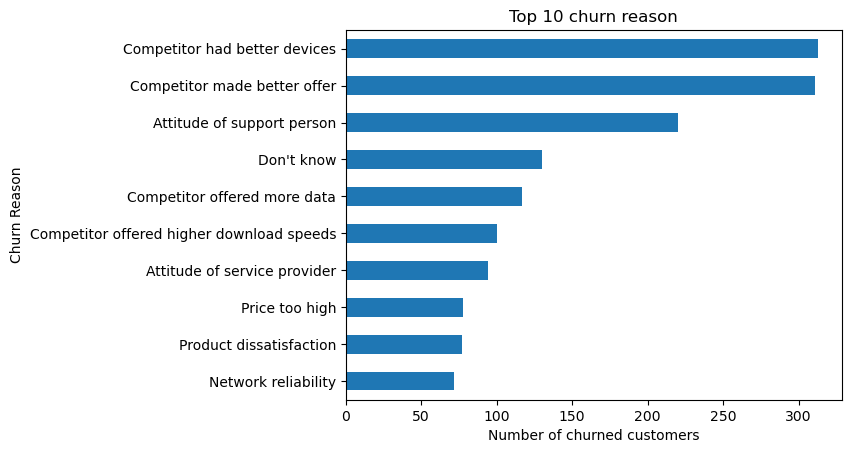

In [80]:
reasons = df_eda['Churn Reason'].value_counts().head(10)
print(reasons)

reasons.plot(kind='barh')
plt.title("Top 10 churn reason")
plt.xlabel("Number of churned customers")
plt.gca().invert_yaxis()

- Competitors drive churn: better devices (313) and better offers (311) are the two biggest reasons,

    - and competitor-related reasons account for at least 45% of all churned customers.

    - Staff attitude is the next biggest cause (220), while “price too high” is minor (78).

$Step-10$: **EDA plot 6, correlation heatmap**

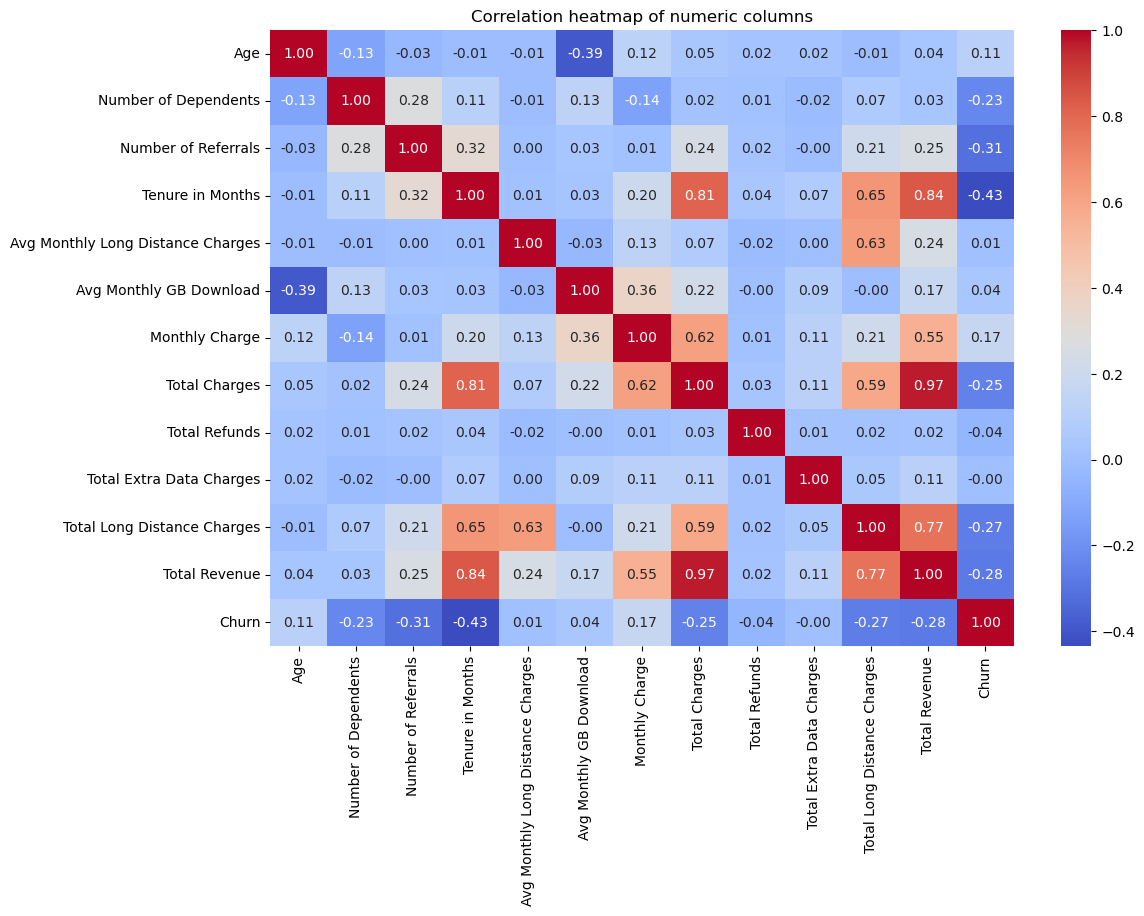

In [92]:
import seaborn as sns
num_df = df_model.select_dtypes(include='number')
corr = num_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation heatmap of numeric columns")
plt.show()

- Tenure has the strongest link with churn (-0.43), followed by number of referrals (-0.31). 
    
   - Customers who stay longer, refer others, or have dependents are less likely to churn, while higher monthly charges slightly increase churn (+0.17).
        

- Month-to-Month customers churn at 51.7%, compared with 10.9% (one year) and 2.6% (two year).
    
- Churn is concentrated in the first few months, and drops steadily as tenure grows.
    
- Churned customers pay more on average (73.35 vs 61.74). Churn is concentrated in the 70-100 range.
    
- Fiber Optic churns the most (42.1%), and customers with no internet churn the least (8.4%).
    
- Competitors drive churn, with at least 45% of churned customers citing competitor reasons. “Price too high” is minor (78).
    
- Tenure has the strongest correlation with churn (-0.43), followed by referrals (-0.31).

In [93]:
df_eda.to_pickle("df_eda.pkl")
df_model.to_pickle("df_model.pkl")